## **EGNA**

In [1]:
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.oneDwellfunctions import *
import time

#Para Bayesian optimization de parámetros
from skopt import gp_minimize
from skopt.space import Integer, Real, Categorical
from skopt.utils import use_named_args

#Para usar EGNA
from EDAspy.optimization import EGNA
from EDAspy.optimization import EMNA
from EDAspy.optimization import SPEDA
from EDAspy.optimization import UMDAc

#Para procesos Gaussianos
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def _normalize(dataset:np.array, grid_size: float):
        '''
        Normalizes the solutions i.e. multiply by a constant so that the integral of the solution^2 = 1.
        Be aware that integration depends on problem definition and size!!!!
        '''
        #grid_size = L/variables     dx of integral
        #grid_size = 5/(self.n_variables-1)

        #Assuming a constant size grid we know grid size independently of problem parameters (better code-wise)
        #self.grid_size = grid_X[-1,0] - grid_X[-2, 0]

        for ind in range(len(dataset)):
                integral = 0
                for var in range(dataset.shape[1]):
                    integral = integral + (dataset[ind,:][var]**2)*grid_size ##Tener en cuenta posibles cambios en tamaño grid!!! L caja = 5 

                A = (1/integral)**0.5
                dataset[ind, :] = A * dataset[ind, :]


In [3]:
def initialize_population(size_gen, grid, init_kernels, init_constraints):
    '''
    SMART initialization for suitable solutions creation.
    Creates the initial population from the desired number of distinct RBF kernels. A 'grid search' is performed over the length scale parameter.
    The minimum value for the length scale is defined depending on the grid size, as lambda = grid_size/sqrt(2). 
    The maximum value is defined as half the total range of the independent variable.
    init_constraints: tuple of tuples with initial known observations or constraints 
               ((grid points x ), (observations f(x))) = ((x_1, x_2, ..., x_m), (f(x_1), f(x_2), ..., f(x_m)))
               both arrays must be shape ((m, 1)) where m=grid points where observations are known. Observations must coincide with some of the points defined in the grid
    '''

    grid_size = grid[-1,0] - grid[-2, 0]
    problem_size = grid[-1,0] - grid[0,0]
            
    lengths = np.linspace(grid_size/np.sqrt(2), problem_size/2, init_kernels)
    samplesperkernel = int(size_gen/init_kernels)
    for scale in lengths:
        kernel = 0.01 * RBF(length_scale=scale,  length_scale_bounds='fixed') #length_scale_bounds=(scale[0], scale[0]))
        gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9)
        gaussian_process.fit(init_constraints[0], init_constraints[1])

        if scale==lengths[0]:
            init_generation=gaussian_process.sample_y(grid, n_samples=samplesperkernel).T
        else:
            init_generation = np.concatenate([init_generation, gaussian_process.sample_y(grid, n_samples=samplesperkernel).T])
    return init_generation

## **Pozo infinito**

In [4]:
n_variables = [50, 425, 800]
from itertools import permutations
#Lista para prohibir todos los arcos y que SPEDA sea por tanto un kernel puro para cada nodo
blacks = [(str(a), str(b)) for a, b in permutations(range(n_variables[0]), 2)]

In [5]:
n_variables = [50, 425, 800]
Resultados = np.empty((1, 9, 5)) 
# 5 métricas [MSE, E, E%, GP_1000, t_exc]
experimento = int(0)    

######################################################################################
######################################################################################
############## POZO DE POTENCIAL INFINITO 1D WELL ####################################
######################################################################################

print('\nInfinite Well IN PROGRESS\n')
L=5
#Energías teóricas
Eg = (2*np.pi)**2/(8*L**2*1)
En=[]
for i in range(4):
    e=(i+1)**2*Eg
    En.append(e)

## Problem grid definition
X_grid = np.linspace(start=0, stop=L, num=n_variables[0]).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=0 x=5 que son 0
X_train = X_grid[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
init_data = None #initialize_population(size_gen=3000, grid=X_grid, init_kernels=10, init_constraints=(X_train, Y_train))
grid_size = X_grid[-1,0] - X_grid[-2, 0]
params = {'L':L}

#Soluciones teóricas
### Soluciones analíticas
# def Psi_n(n):
#     return((2/L)**0.5*np.sin(n*np.pi*np.linspace(0, L, n_variables)/L))

APsisWell = {}
for n in range(4):
    APsisWell[f'APsi{n}'] = (2/L)**0.5*np.sin((n+1)*np.pi*np.linspace(0, L, n_variables[0])/L)

##################################################################
######### MANDATORY ARCS for GBN structure #######################
##################################################################
#ARCOS cadena simple
#whites es una lista con los arcos obligatorios que aprender
#'Continuidad de la función'
# whites1=[(str(i), str(i+1)) for i in range(n_variables[0]-1)]

#ARCOS [(0, 50), (1, 49), (2, 48), ..., (23, 27), (24, 26)] conectando puntos extremos (simetría)
# #simetría de la función SOLO PARA OSCILADOR SI ACASO
# whites2=[(str(i), str(n_variables[0]-i-1)) for i in range((n_variables[0]//2))]

# whites=whites1 +whites2
# #print(whites)

#ARCOS de extremos a centro (de evidencias a centro)
whites1=[(str(i), str(i-1)) for i in range(n_variables[0]-1,n_variables[0]//2, -1)]
whites2=[(str(i), str(i+1)) for i in range(0, n_variables[0]//2, 1)]
whites = whites1 + whites2
print(whites)
##################################################################


##################################################################################
############### A L G O R I T M O   D E   O P T I M I Z A C I Ó N  ###############
##################################################################################
### No funciona de esta manera, hay que reinstanciarlo cada vez que se usa
#algoritmo = EGNA(size_gen=3000, max_iter=450, dead_iter=60, n_variables= n_variables[0], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
# algoritmo = EMNA(size_gen=5000, max_iter=800, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True)#, upper_factor=0.6)#, lower_factor=0.01)
# algoritmo = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks)
###############################    
#Ground state n=1
###############################
print(f'F should be approx -0.9618')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[0], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=60, n_variables= n_variables[0], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultgroundWell = qegna.minimize(oneD_wellExpE, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 4, 4] = end-start
_normalize(dataset=egnaresultgroundWell.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
Psi_fund=egnaresultgroundWell.sel_inds_hist[-1, 0, :-1]
E_fund = np.sqrt(-np.log(-egnaresultgroundWell.sel_inds_hist[-1,0,-1])) # def exponencial de función de coste la energía se determina a partir del fitness así.
#En este caso no hay constante multiplicando exponente exponencial
Resultados[experimento, 4, 1] = E_fund
Resultados[experimento, 4, 2] = abs(E_fund-En[0])/En[0]*100 

params = {'L':L, 'E': E_fund, 'Psi': Psi_fund}
print(f'\n  |Psi0> done\n')

###############################   
#1excitated state n=2
###############################   
print(f'F should be approx -0.7042')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[0], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=60, n_variables= n_variables[0], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultWellexc1 = qegna.minimize(oneD_wellExpEexcitated, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 5, 4] = end-start
_normalize(dataset=egnaresultWellexc1.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
Psi_1=egnaresultWellexc1.sel_inds_hist[-1, 0, :-1]
E1 = np.sqrt(-np.log(-egnaresultWellexc1.sel_inds_hist[-1,0,-1]))
Resultados[experimento, 5, 1] = E_fund + E1
Resultados[experimento, 5, 2] = abs(E_fund + E1 -En[1])/En[1]*100

params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1}
print(f'\n  |Psi1> done\n')

###############################   
#2nd excitated state n=3
###############################   
print(f'F should be approx -0.3775')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[0], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=60, n_variables= n_variables[0], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultWellexc2 = qegna.minimize(oneD_wellExpEexcitated3, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 6, 4] = end - start
_normalize(dataset=egnaresultWellexc2.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
Psi_2=egnaresultWellexc2.sel_inds_hist[-1, 0, :-1]
E2 = np.sqrt(-np.log(-egnaresultWellexc2.sel_inds_hist[-1,0,-1]))
Resultados[experimento, 6, 1] = E_fund + E1 + E2
Resultados[experimento, 6, 2] = abs(E_fund + E1 +E2 -En[2])/En[2]*100

params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2}
print(f'\n  |Psi2> done\n')

###############################   
#3rd excitated state n=4
###############################   
print(f'F should be approx -0.1482')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[0], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=60, n_variables= n_variables[0], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[0], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultWellexc3 = qegna.minimize(oneD_wellExpEexcitated4, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 7, 4] = end-start
_normalize(dataset=egnaresultWellexc3.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
Psi_3 = egnaresultWellexc3.sel_inds_hist[-1, 0, :-1]
E3 = np.sqrt(-np.log(-egnaresultWellexc3.sel_inds_hist[-1,0,-1]))
Resultados[experimento, 7, 1] = E_fund + E1 + E2 + E3
Resultados[experimento, 7, 2] = abs(E_fund + E1 +E2+E3 -En[3])/En[3]*100

params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2, 'E3':E3, 'Psi3': Psi_3}
print(f'\n  |Psi3> done\n')

#Cálculos de métricas error MSE de cada estado con estado teórico
MSEs = []
for i in range(4):
    mse = min(np.mean((params[f'Psi{i}'] - APsisWell[f'APsi{i}'])**2), np.mean((-1*params[f'Psi{i}'] - APsisWell[f'APsi{i}'])**2))
    Resultados[experimento, i+4, 0] = mse
    MSEs.append(mse)


print('\nInfinite Well DONE\n')


Infinite Well IN PROGRESS

[('49', '48'), ('48', '47'), ('47', '46'), ('46', '45'), ('45', '44'), ('44', '43'), ('43', '42'), ('42', '41'), ('41', '40'), ('40', '39'), ('39', '38'), ('38', '37'), ('37', '36'), ('36', '35'), ('35', '34'), ('34', '33'), ('33', '32'), ('32', '31'), ('31', '30'), ('30', '29'), ('29', '28'), ('28', '27'), ('27', '26'), ('26', '25'), ('0', '1'), ('1', '2'), ('2', '3'), ('3', '4'), ('4', '5'), ('5', '6'), ('6', '7'), ('7', '8'), ('8', '9'), ('9', '10'), ('10', '11'), ('11', '12'), ('12', '13'), ('13', '14'), ('14', '15'), ('15', '16'), ('16', '17'), ('17', '18'), ('18', '19'), ('19', '20'), ('20', '21'), ('21', '22'), ('22', '23'), ('23', '24'), ('24', '25')]
F should be approx -0.9618
IT:  0 	Best cost:  2334.070231152371
IT:  1 	Best cost:  1121.7732541824175
IT:  2 	Best cost:  829.4441808012016
IT:  3 	Best cost:  34.80227475575253
IT:  4 	Best cost:  21.38749894952675
IT:  5 	Best cost:  21.38749894952675
IT:  6 	Best cost:  16.62378968509991
IT:  7 	Be

In [6]:
MSEs

[np.float64(0.011028798384772463),
 np.float64(0.015356030039654658),
 np.float64(0.02619299602618662),
 np.float64(0.38184901325771675)]

<>:12: SyntaxWarning: invalid escape sequence '\P'
<>:12: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_19354/1030137722.py:12: SyntaxWarning: invalid escape sequence '\P'
  plt.gca().set_title('Función de onda $\Psi(x)$')
/tmp/ipykernel_19354/1030137722.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc = 'upper right')


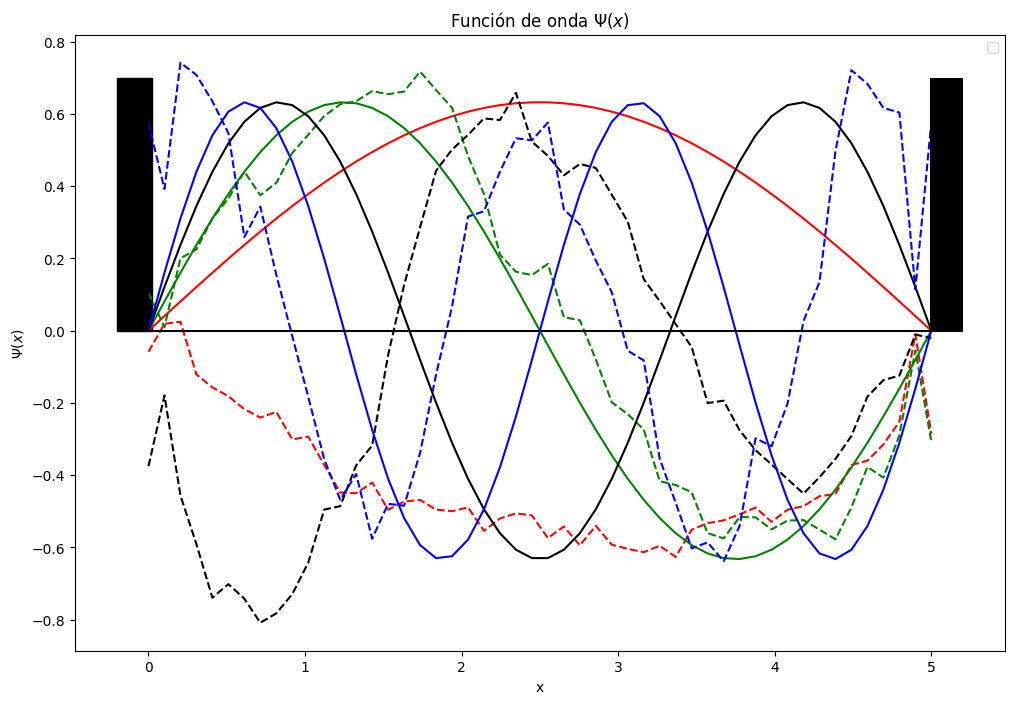

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
c = ['r', 'g', 'k', 'b']
for i in range(4):
    plt.plot(np.linspace(0, 5, n_variables[0]), params[f'Psi{i}'], f'{c[i]}--') 
    plt.plot(np.linspace(0, 5, n_variables[0]), APsisWell[f'APsi{i}'], f'{c[i]}-')

# plt.plot(np.linspace(0, 5, n_variables),resultegna.sel_inds_hist[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
# plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'r--', label='Sol. analítica')
plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, 0.02, 0.02]
x2 = [5.0, 5.0, 5.2, 5.2]
y = [0, 0.7, 0.7, 0]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

<>:12: SyntaxWarning: invalid escape sequence '\P'
<>:12: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_19354/2847418254.py:12: SyntaxWarning: invalid escape sequence '\P'
  plt.gca().set_title('Función de onda $\Psi(x)$')
/tmp/ipykernel_19354/2847418254.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc = 'upper right')


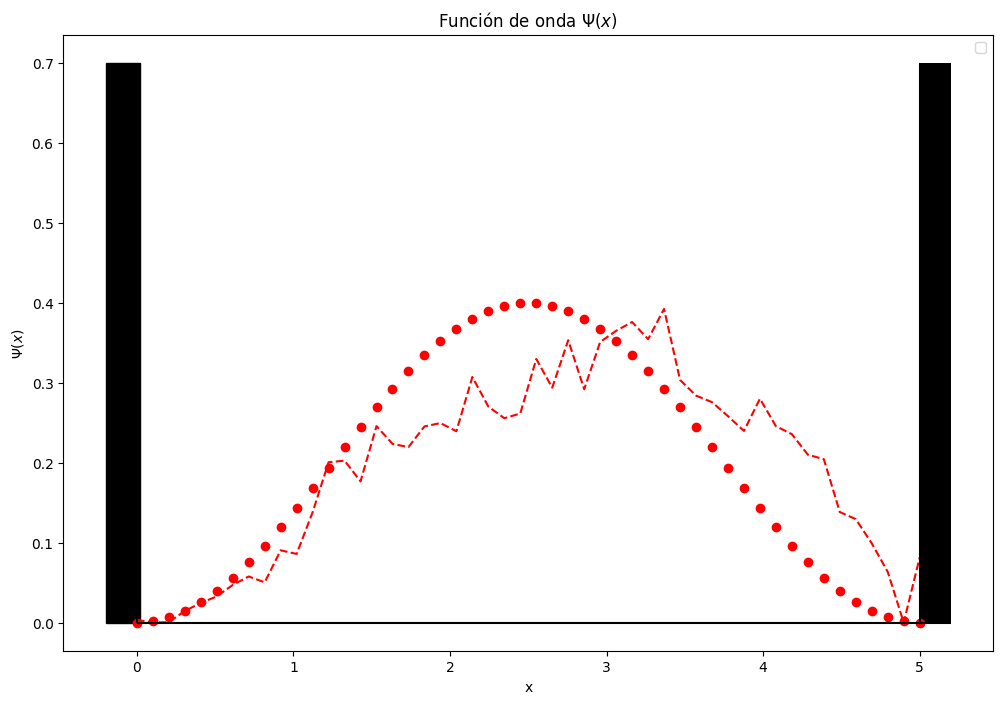

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
f=0
c = ['r', 'g', 'k', 'b']
plt.plot(np.linspace(0, 5, n_variables[0]), params[f'Psi{f}']**2, f'{c[f]}--') 
plt.plot(np.linspace(0, 5, n_variables[0]), APsisWell[f'APsi{f}']**2, f'{c[f]}o')

# plt.plot(np.linspace(0, 5, n_variables),resultegna.sel_inds_hist[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
# plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'r--', label='Sol. analítica')
plt.vlines(x=0, ymin=0, ymax=0.7, colors='black')
plt.vlines(x=5, ymin=0, ymax=0.7, colors='black')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, 0.02, 0.02]
x2 = [5.0, 5.0, 5.2, 5.2]
y = [0, 0.7, 0.7, 0]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [9]:
print(PARA)

NameError: name 'PARA' is not defined

## Oscilador armónico

In [10]:
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.oneDQHarmOscillatorfunctions import *
import time

#Para Bayesian optimization de parámetros
from skopt import gp_minimize
from skopt.space import Integer, Real, Categorical
from skopt.utils import use_named_args

#Para usar EGNA
from EDAspy.optimization import EGNA
from EDAspy.optimization import UMDAc
from EDAspy.optimization import EMNA

#Para procesos Gaussianos
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

import pandas as pd
import matplotlib.pyplot as plt

In [11]:
def _normalize(dataset:np.array, grid_size: float):
    '''
    Normalizes the solutions i.e. multiply by a constant so that the integral of the solution^2 = 1.
    Be aware that integration depends on problem definition and size!!!!
    '''
    #grid_size = L/variables     dx of integral
    #grid_size = 5/(self.n_variables-1)

    #Assuming a constant size grid we know grid size independently of problem parameters (better code-wise)
    #self.grid_size = grid_X[-1,0] - grid_X[-2, 0]

    for ind in range(len(dataset)):
            integral = 0
            for var in range(dataset.shape[1]):
                integral = integral + (dataset[ind,:][var]**2)*grid_size ##Tener en cuenta posibles cambios en tamaño grid!!! L caja = 5 

            A = (1/integral)**0.5
            dataset[ind, :] = A * dataset[ind, :] 


In [ ]:

n_variables = [50, 425, 800]
Resultados = np.empty((1, 9, 5)) 
# 5 métricas [MSE, E, E%, GP_1000, t_exc]
experimento = int(0)

##Lo siguiente no funciona, hay que instanciar los algoritmos cada vez que se usan
#algoritmo = UMDAc(size_gen=3200, max_iter=1000, dead_iter=501, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True)
#algoritmo = EMNA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True)
#whites es una lista con los arcos obligatorios que aprender
##################################################################
######### MANDATORY ARCS for GBN structure #######################
##################################################################
#ARCOS cadena simple
#whites es una lista con los arcos obligatorios que aprender
#'Continuidad de la función'
# whites1=[(str(i), str(i+1)) for i in range(n_variables[1]-1)]

#ARCOS [(0, 50), (1, 49), (2, 48), ..., (23, 27), (24, 26)] conectando puntos extremos (simetría)
# #simetría de la función SOLO PARA OSCILADOR SI ACASO
# whites2=[(str(i), str(n_variables[1]-i-1)) for i in range((n_variables[1]//2))]

# whites=whites1 +whites2
# #print(whites)

#ARCOS de extremos a centro (de evidencias a centro)
whites1=[(str(i), str(i-1)) for i in range(n_variables[1]-1,n_variables[1]//2, -1)]
whites2=[(str(i), str(i+1)) for i in range(0, n_variables[1]//2, 1)]
whites = whites1 + whites2
print(whites)
##################################################################

init_data = None #initialize_population(size_gen=3000, grid=X_grid, init_kernels=10, init_constraints=(X_train, Y_train))

##########################################################################################
##########################################################################################
########################### OSCILADOR ARMÓNICO ###########################################
##########################################################################################
print('Quantum Harmonic Oscillator IN PROGRESS\n')
#Problem grid definition
X_grid = np.linspace(start=-4, stop=4, num=n_variables[1]).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=-4 (-inf) x=4 (inf) que son 0
X_train = X_grid[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array

#Analytical solutions definitions
#Ground state
APsi0 = np.exp(-X_grid**2/2)
integral =0
for i in range(len(APsi0)):
    integral = integral + (APsi0[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi0)-1))

B = (1/integral)**0.5
APsi0 = B * APsi0

#1st excitated state
APsi1 = np.exp(-X_grid**2/2)*2*X_grid
integral =0
for i in range(len(APsi1)):
    integral = integral + (APsi1[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi1)-1))

B = (1/integral)**0.5
APsi1 = -1 * B * APsi1 #signo menos para correspondencia con solución algoritmo (simetrización)

#2nd excitated state
APsi2 = np.exp(-X_grid**2/2)*(4*X_grid**2-2)
integral =0
for i in range(len(APsi2)):
    integral = integral + (APsi2[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi2)-1))

B = (1/integral)**0.5
APsi2 = B * APsi2

#3rd excitated state
APsi3 = np.exp(-X_grid**2/2)*(8*X_grid**3-12*X_grid)
integral =0
for i in range(len(APsi3)):
    integral = integral + (APsi3[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi3)-1))

B = (1/integral)**0.5
APsi3 = -1 * B * APsi3 #signo menos para correspondencia con solución algoritmo (simetrización)

APsis = {}
APsis['APsi0'] = APsi0[:, 0]
APsis['APsi1'] = APsi1[:, 0]
APsis['APsi2'] = APsi2[:, 0]
APsis['APsi3'] = APsi3[:, 0]
X_grid = X_grid[:, 0]
grid_size = X_grid[-1] - X_grid[-2]

##########################################################################################################
##########################################################################################################

### Ahora el código con EGPA que calcula los 4 primeros estados excitados del problema oscilador armónico
params = {'x':X_grid}
#Ground state
print(f'F should be approx -0.082')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[1], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=201, n_variables= n_variables[1], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultQHOground = qegna.minimize(oneDHOExpE, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 0, 4] = end-start
_normalize(dataset=egnaresultQHOground.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
#Se guardan resultados de algoritmo para siguiente estado excitado
Psi_ground=egnaresultQHOground.sel_inds_hist[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E0 = np.sqrt(-np.log(-egnaresultQHOground.sel_inds_hist[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así 
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground}
Resultados[experimento, 0, 1] = E0
Resultados[experimento, 0, 2] = abs(E0-0.5)/0.5*100

print(f'\n  |Psi0> done\n')

#1er estado excitado
print(f'F should be approx -4.54e-5')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[1], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=201, n_variables= n_variables[1], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultQHO1 = qegna.minimize(oneDHOExpE1, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 1, 4] = end-start
_normalize(dataset=egnaresultQHO1.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
Psi1=egnaresultQHO1.sel_inds_hist[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E1 = np.sqrt(-np.log(-egnaresultQHO1.sel_inds_hist[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
Resultados[experimento, 1, 1] = E0 + E1
Resultados[experimento, 1, 2] = abs(E0 + E1 -1.5)/1.5*100
 
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1}
print(f'\n  |Psi1> done\n')

#2o estado excitado
print(f'F should be approx -4.54e-5')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[1], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=201, n_variables= n_variables[1], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultQHO2 = qegna.minimize(oneDHOExpE2, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 2, 4] = end-start
_normalize(dataset=egnaresultQHO2.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
Psi2=egnaresultQHO2.sel_inds_hist[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E2 = np.sqrt(-np.log(-egnaresultQHO2.sel_inds_hist[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
Resultados[experimento, 2, 1] = E0 + E1 + E2
Resultados[experimento, 2, 2] = abs(E0 + E1 + E2 -2.5)/2.5*100
  
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1, 'E2':E2, 'Psi2': Psi2 }
print(f'\n  |Psi2> done\n')

#3er estado excitado
print(f'F should be approx -4.54e-5')
#qegna = UMDAc(size_gen=3000, max_iter=800, dead_iter=201, n_variables=n_variables[1], lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=201, n_variables= n_variables[1], lower_bound=-1, upper_bound = 1, alpha=0.6, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= n_variables[1], lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egnaresultQHO3 = qegna.minimize(oneDHOExpE3, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 3, 4] = end-start
_normalize(dataset=egnaresultQHO3.sel_inds_hist[-1, :,:-1], grid_size=grid_size)
Psi3=egnaresultQHO3.sel_inds_hist[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E3 = np.sqrt(-np.log(-egnaresultQHO3.sel_inds_hist[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
Resultados[experimento, 3, 1] = E0 + E1 + E2 + E3
Resultados[experimento, 3, 2] = abs(E0 + E1 + E2 + E3 -3.5)/3.5*100
 
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1, 'E2':E2, 'Psi2': Psi2, 'E3': E3, 'Psi3': Psi3 }
print(f'\n  |Psi3> done\n')

#Cálculos de métricas error MSE de cada estado con estado teórico
MSEs = []
for i in range(4):
    mse = min(np.mean((params[f'Psi{i}'] - APsis[f'APsi{i}'])**2), np.mean((-1*params[f'Psi{i}'] - APsis[f'APsi{i}'])**2))
    Resultados[experimento, i, 0] = mse
    MSEs.append(mse)

[('424', '423'), ('423', '422'), ('422', '421'), ('421', '420'), ('420', '419'), ('419', '418'), ('418', '417'), ('417', '416'), ('416', '415'), ('415', '414'), ('414', '413'), ('413', '412'), ('412', '411'), ('411', '410'), ('410', '409'), ('409', '408'), ('408', '407'), ('407', '406'), ('406', '405'), ('405', '404'), ('404', '403'), ('403', '402'), ('402', '401'), ('401', '400'), ('400', '399'), ('399', '398'), ('398', '397'), ('397', '396'), ('396', '395'), ('395', '394'), ('394', '393'), ('393', '392'), ('392', '391'), ('391', '390'), ('390', '389'), ('389', '388'), ('388', '387'), ('387', '386'), ('386', '385'), ('385', '384'), ('384', '383'), ('383', '382'), ('382', '381'), ('381', '380'), ('380', '379'), ('379', '378'), ('378', '377'), ('377', '376'), ('376', '375'), ('375', '374'), ('374', '373'), ('373', '372'), ('372', '371'), ('371', '370'), ('370', '369'), ('369', '368'), ('368', '367'), ('367', '366'), ('366', '365'), ('365', '364'), ('364', '363'), ('363', '362'), ('362',

<>:9: SyntaxWarning: invalid escape sequence '\P'
<>:9: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_284958/2810103110.py:9: SyntaxWarning: invalid escape sequence '\P'
  plt.plot(X_grid, e+params[f'Psi{i}'], 'b-', label=f'$\Psi(x)$', alpha=0.9)


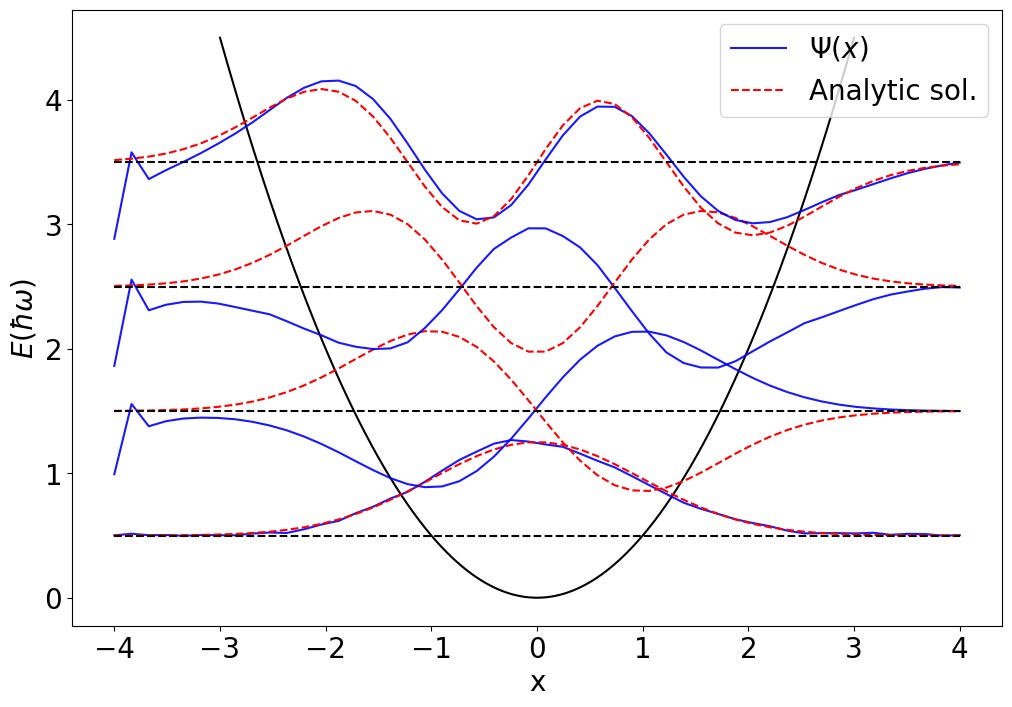

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.rcParams.update({'font.size':20})
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')

e = 0.5
for i in range(4):
    if i == 3:
        plt.plot(X_grid, e+params[f'Psi{i}'], 'b-', label=f'$\Psi(x)$', alpha=0.9)
        plt.plot(np.linspace(-4,4,n_variables[0]), e+APsis[f'APsi{i}'], 'r--', label='Analytic sol.')
        plt.plot(np.linspace(-4,4,2), np.linspace(e,e,2), 'k--')
        e+=1
    else:
        plt.plot(X_grid, e+params[f'Psi{i}'], 'b-', alpha=0.9)
        plt.plot(np.linspace(-4,4,n_variables[0]), e+APsis[f'APsi{i}'], 'r--')
        plt.plot(np.linspace(-4,4,2), np.linspace(e,e,2), 'k--')
        e+=1


#plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E (\hbar \omega)$')
plt.legend(loc = 'upper right');
#plt.savefig('Figures/QHObyEGPAbigfont.pdf');

In [ ]:
MSEs

## NLSE

In [17]:
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.NonLinearSE import *
import time

#Para Bayesian optimization de parámetros
from skopt import gp_minimize
from skopt.space import Integer, Real, Categorical
from skopt.utils import use_named_args

#Para usar EGNA
from EDAspy.optimization import EGNA
from EDAspy.optimization import UMDAc
from EDAspy.optimization import EMNA

#Para procesos Gaussianos
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
######################################################################################
######################################################################################
#################### N L S E Non linear Schroedinger Equation ########################
######################################################################################
print('\nNLSE IN PROGRESS\n')
n_variables = [50, 425, 800]

Resultados = np.empty((1, 9, 5)) 
# 5 métricas [MSE, E, E%, GP_1000, t_exc]
experimento = int(0)   

L=2
#El grid se define en para los tres problemas de optimización con el mismo número de variables
if n_variables[1]%2 ==0:
    varsNLSE=n_variables[1]+1
else:
    varsNLSE=n_variables[1]

X_grid = np.linspace(start=-1, stop=1, num=varsNLSE).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=0 que son 1
#X_train = X_grid[n_variables//2]
X_train = np.array((0)).reshape(-1,1)
Y_train = np.linspace(start=1, stop=1, num=1).reshape(-1,1) #Para que sea 2D array
##################################################################
######### MANDATORY ARCS for GBN structure #######################
##################################################################
#ARCOS cadena simple
#whites es una lista con los arcos obligatorios que aprender
#'Continuidad de la función'
# whites1=[(str(i), str(i+1)) for i in range(n_variables[0]-1)]

#ARCOS [(0, 50), (1, 49), (2, 48), ..., (23, 27), (24, 26)] conectando puntos extremos (simetría)
# #simetría de la función SOLO PARA OSCILADOR SI ACASO
# whites2=[(str(i), str(n_variables[0]-i-1)) for i in range((n_variables[0]//2))]

# whites=whites1 +whites2
# #print(whites)
##################################################################

#whites es una lista con los arcos obligatorios que aprender
#simetría de función desde punto central (condición de contorno)
whites1=[(str(i), str(i-1)) for i in range((varsNLSE//2),0, -1)]
whites2=[(str(i), str(i+1)) for i in range(varsNLSE//2,varsNLSE-1, 1)]
whites = whites1 + whites2

init_data = None #initialize_population(size_gen=3000, grid=X_grid, init_kernels=10, init_constraints=(X_train, Y_train))
params = {'L':L}
#qegna = UMDAc(size_gen=3000, max_iter=600, dead_iter=201, n_variables=varsNLSE, lower_bound=-1, upper_bound=1, alpha=0.4)#, lower_factor=0.01)
qegna = EGNA(size_gen=3000, max_iter=450, dead_iter=201, n_variables= varsNLSE, lower_bound=0, upper_bound = 2, alpha=0.2, parallelize=True, white_list=whites, init_data=init_data)
#qegna = EMNA(size_gen=3200, max_iter=600, dead_iter=201, n_variables= varsNLSE, lower_bound=-0.5, upper_bound = 0.5, alpha=0.4, parallelize=True)#, lower_factor = 0.3)#, upper_factor=0.6)#, lower_factor=0.01)
#qegna = SPEDA(size_gen=3200, max_iter=800, dead_iter=201, n_variables= varsNLSE, lower_bound=-0.5, upper_bound = 0.5, alpha=0.6, parallelize=True, l=0, black_list=blacks) 
start = time.time()
egparesultNLSE = qegna.minimize(NLSE, params, exp_from = 20, output_runtime=True)
end = time.time()
Resultados[experimento, 8, 4] = end-start
#MSE calc
#MSE_NLSE = sum((1/np.cosh(X_grid[:,0]) - egparesultNLSE.data[-1, 0, :-1])**2) / len(X_grid[:,0])
#print(MSE_NLSE, 'using sum')
MSE_NLSE = np.sum((1/np.cosh(X_grid[:,0]) - egparesultNLSE.sel_inds_hist[-1, 0, :-1])**2) / len(X_grid[:,0])
MSE_NLSE = np.float64(MSE_NLSE)
Resultados[experimento, 8, 0] = MSE_NLSE
#setting non used columns to None
Resultados[experimento, 8, 1:3] = None
Resultados[experimento, :, 3] = None
print('\nNLSE DONE\n')
##################################################################################################


NLSE IN PROGRESS



IT:  0 	Best cost:  982678255.45643246564
IT:  1 	Best cost:  926030687.42363971553
IT:  2 	Best cost:  858975850.7825383613
IT:  3 	Best cost:  800094771.9082175105
IT:  4 	Best cost:  757379766.11482624523
IT:  5 	Best cost:  700583043.6850139802
IT:  6 	Best cost:  682179010.06987613975
IT:  7 	Best cost:  635435576.2639071237
IT:  8 	Best cost:  613336736.5162797168
IT:  9 	Best cost:  561341220.2871378716
IT:  10 	Best cost:  543987238.3208370375
IT:  11 	Best cost:  515939396.94587510423
IT:  12 	Best cost:  500022723.1822352885
IT:  13 	Best cost:  480497262.49329572497
IT:  14 	Best cost:  446214517.24483947322
IT:  15 	Best cost:  414269331.73078531265
IT:  16 	Best cost:  405009959.48084437568
IT:  17 	Best cost:  382526072.15343486945
IT:  18 	Best cost:  368465062.50410778585
IT:  19 	Best cost:  -0.0
IT:  20 	Best cost:  -0.0
IT:  21 	Best cost:  -0.0
IT:  22 	Best cost:  -0.0
IT:  23 	Best cost:  -0.0
IT:  24 	Best cost:  -0.0
IT:  25 	Best cost:  -0.0
IT:  26 	Best cost:

<>:3: SyntaxWarning: invalid escape sequence '\P'
<>:5: SyntaxWarning: invalid escape sequence '\P'
<>:3: SyntaxWarning: invalid escape sequence '\P'
<>:5: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_284958/4216380279.py:3: SyntaxWarning: invalid escape sequence '\P'
  plt.plot(np.linspace(-1, 1, varsNLSE), egparesultNLSE.sel_inds_hist[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
/tmp/ipykernel_284958/4216380279.py:5: SyntaxWarning: invalid escape sequence '\P'
  plt.gca().set_title('Función de onda $\Psi(x)$')


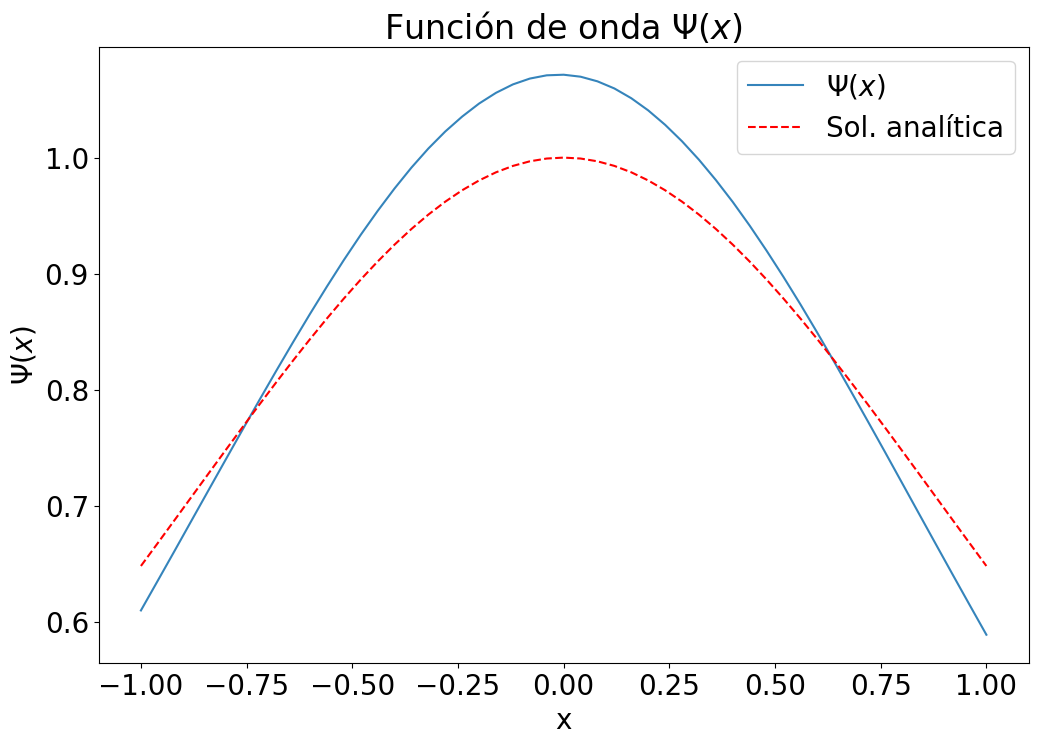

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.plot(np.linspace(-1, 1, varsNLSE), egparesultNLSE.sel_inds_hist[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-1, 1, varsNLSE), 1/np.cosh(X_grid[:,0]), 'r--', label='Sol. analítica')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'best');

In [ ]:
import numpy as np
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
import pickle

ruta = '../EGPA_1D_experiments/ResultadosEXP/425EGPA'
with open(f'{ruta}.pkl', "rb") as file:
    BO_params = pickle.load(file)

BO_params[:,8,4]


np.float64(3.811820280253887)